# Reproducing Figure 3

Loading data:

In [16]:
import sys
from pathlib import Path
import json

sys.path.append(str(Path.cwd().parent))  # enables importing from src/

from src.load_datasets import load_abstracts_and_summaries, load_pos, DATASETS, DATA_DIR, SPLITS, DOCUMENT_TYPES

import spacy

import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import numpy as np

In [3]:
data = load_abstracts_and_summaries()

## Tagging abstracts and summaries with the ScispaCy POS-tagger

Loading POS-tagger:

In [5]:
nlp = spacy.load("en_core_sci_scibert", disable=["ner", "parser"])

c:\Users\uleno\OneDrive\ITU\SDS\Reproducibility Challenge\Reproducing-Making-Science-Simple\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\uleno\OneDrive\ITU\SDS\Reproducibility Challenge\Reproducing-Making-Science-Simple\.venv\Lib\site-packages\spacy\language.py:2195: FutureWarning: Possible set union at position 6328
  deserializers["tokenizer"] = lambda p: self.tokenizer.from_disk(  # type: ignore[union-attr]


Testing with one summary:

In [3]:
print(data["elife"]["summaries"][0])

CONTENT_POS = {"NOUN", "PROPN", "VERB", "NUM"}

content_words = []
for doc in nlp.pipe([data["elife"]["summaries"][0]], batch_size=64):
    content_words.append([(tok.text, tok.pos_) for tok in doc if tok.pos_ in CONTENT_POS])

print(content_words)

In the USA , more deaths happen in the winter than the summer . But when deaths occur varies greatly by sex , age , cause of death , and possibly region . Seasonal differences in death rates can change over time due to changes in factors that cause disease or affect treatment . Analyzing the seasonality of deaths can help scientists determine whether interventions to minimize deaths during a certain time of year are needed , or whether existing ones are effective . Scrutinizing seasonal patterns in death over time can also help scientists determine whether large-scale weather or climate changes are affecting the seasonality of death . Now , Parks et al . show that there are age and sex differences in which times of year most deaths occur . Parks et al . analyzed data on US deaths between 1980 and 2016 . While overall deaths in a year were highest in winter and lowest in summer , a greater number of young men died during summer – mainly due to injuries – than during winter . Seasonal di

NameError: name 'nlp' is not defined

Tagging and saving all POS data:

In [3]:

# for each data set
for ds in data:  # data
    out_path = DATA_DIR / "POS" / f"{ds}_pos.json"
    if out_path.exists():
        print(f"{out_path} exists, skipping")
        continue

    tagged = {}

    # for each document type
    for document_type in DOCUMENT_TYPES:

        tagged[document_type] = []

        # for each output of the POS-tagger
        for doc in nlp.pipe(data[ds][document_type], batch_size=64):

            # save text as lower case lemma. This ensures e.g. "Cells" and "cell" match.
            text_and_pos = [(tok.lemma_.lower(), tok.pos_) for tok in doc]  

            tagged[document_type].append(text_and_pos)

    # saving data set POS data
    out_path.parent.mkdir(parents=True, exist_ok=True)

    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(tagged, f)
    print(f"Saved {out_path}")

..\data\POS\elife_pos.json exists, skipping
..\data\POS\plos_pos.json exists, skipping


## Loading and processing POS datasets

In [4]:
pos_data = load_pos()

In [5]:
pos_data["elife"]["abstracts"][0][:10]

[['in', 'ADP'],
 ['temperate', 'ADJ'],
 ['climate', 'NOUN'],
 [',', 'PUNCT'],
 ['winter', 'NOUN'],
 ['death', 'NOUN'],
 ['exceed', 'VERB'],
 ['summer', 'NOUN'],
 ['one', 'NOUN'],
 ['.', 'PUNCT']]

Construct dataframe with each row (paper, abstract content word) having a “shared” flag if abstract word also exists in summaries:

In [ ]:
CONTENT_POS = {"NOUN", "PROPN", "VERB", "NUM"}

rows = []

for ds in pos_data:
    abstracts = pos_data[ds]["abstracts"]
    summaries = pos_data[ds]["summaries"]

    for pid, (abs_tokens, sum_tokens) in enumerate(zip(abstracts, summaries)):
        summary_words = {lemma for lemma, _ in sum_tokens}
        abstract_types = {(lemma, pos) for lemma, pos in abs_tokens if pos in CONTENT_POS}

        for lemma, pos in abstract_types:
            rows.append((ds, pid, lemma, pos, lemma in summary_words))

words = pd.DataFrame(rows, columns=["dataset", "pid", "word", "pos", "shared"])

In [9]:
words[:10]

,dataset,pid,word,pos,shared
0,elife,0,2016,NUM,True
1,elife,0,group,NOUN,True
2,elife,0,mortality,NOUN,False
3,elife,0,45,NUM,True
4,elife,0,cause,NOUN,True
5,elife,0,use,VERB,True
6,elife,0,rate,NOUN,True
7,elife,0,magnitude,NOUN,False
8,elife,0,year,NOUN,True
9,elife,0,minimum,NOUN,False


Processing words df by counting, grouping and averaging to prepare data for the vizualization:

In [ ]:
BINS = ["1", "2-10", "11-100", "100+"]

# Number of abstract occurences per word
words["n_abstracts"] = words.groupby(["dataset", "word"])["pid"].transform("nunique")

# Bin of number of abstract occurences
words["bin"] = pd.cut(words["n_abstracts"], 
                      [0, 1, 10, 100, float("inf")], 
                      labels=BINS).astype(str)

# Getting counts for word type per POS type
counts = (words.groupby(["dataset", "pid", "pos", "bin", "shared"]).size()
               .unstack(["bin", "shared"], fill_value=0))

# Percentage of counts
pct = counts.div(counts.sum(axis=1), axis=0) * 100

# Averaging per POS type
avg = (pct.groupby(["dataset", "pos"]).mean()
          .reindex(columns=pd.MultiIndex.from_product([BINS, [False, True]]), fill_value=0))

In [20]:
words

,dataset,pid,word,pos,shared,n_abstracts,bin
0,elife,0,2016,NUM,True,13,11-100
1,elife,0,group,NOUN,True,181,100+
2,elife,0,mortality,NOUN,False,52,11-100
3,elife,0,45,NUM,True,12,11-100
4,elife,0,cause,NOUN,True,555,100+
...,...,...,...,...,...,...,...
2288246,plos,27524,geometry,NOUN,False,130,100+
2288247,plos,27524,landscape,NOUN,False,414,100+
2288248,plos,27524,span,VERB,False,336,100+
2288249,plos,27524,state,NOUN,False,2037,100+


## Visualizing Figure 3

Vis settings:

In [14]:
plt.rcParams.update({"font.family": "serif", "hatch.color": "white"})

POS_ORDER = ["NOUN", "PROPN", "NUM", "VERB"]
POS_NAMES = {"NOUN": "Noun", "PROPN": "Proper noun", "NUM": "Number", "VERB": "Verb"}
HATCH = {"NOUN": "\\/", "PROPN": "\\\\", "NUM": "o", "VERB": ".."}
COLORS = {False: "#5f9ea0", True: "#00007f"}
width = 0.2

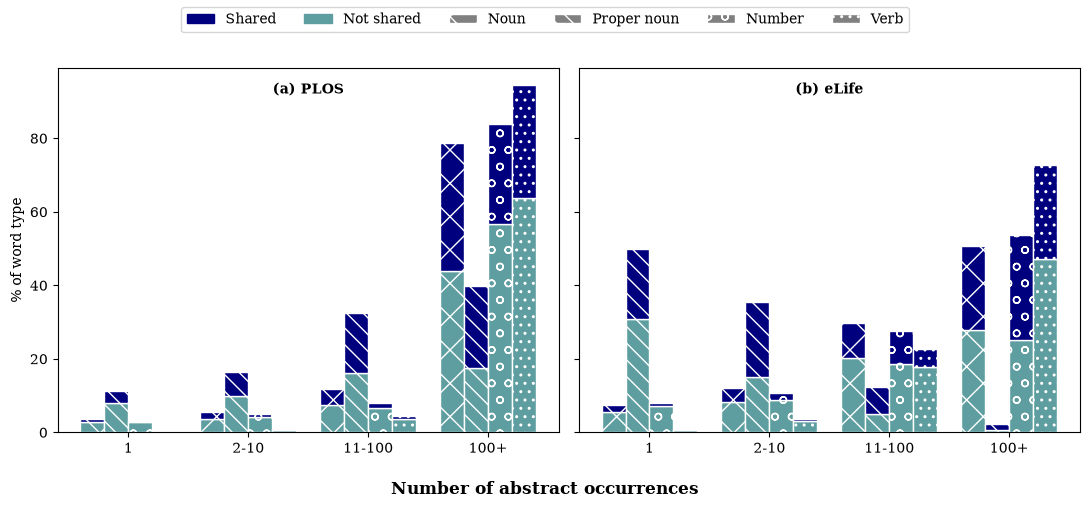

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for ax, ds, title in zip(axes, ["plos", "elife"], ["(a) PLOS", "(b) eLife"]):
    for j, pos in enumerate(POS_ORDER):
        x = np.arange(len(BINS)) + (j - 1.5) * width
        not_shared = [avg.loc[(ds, pos), (b, False)] for b in BINS]
        shared = [avg.loc[(ds, pos), (b, True)] for b in BINS]
        ax.bar(x, not_shared, width, color=COLORS[False], hatch=HATCH[pos], edgecolor="white")
        ax.bar(x, shared, width, bottom=not_shared, color=COLORS[True], hatch=HATCH[pos], edgecolor="white")
    ax.set_xticks(range(len(BINS)), BINS)
    ax.text(0.5, 0.93, title, transform=ax.transAxes, ha="center", fontweight="bold")

axes[0].set_ylabel("% of word type")
fig.supxlabel("Number of abstract occurrences", fontweight="bold")

handles = [Patch(color=COLORS[True], label="Shared"), Patch(color=COLORS[False], label="Not shared")]
handles += [Patch(facecolor="grey", hatch=HATCH[p], edgecolor="white", label=POS_NAMES[p]) for p in POS_ORDER]
fig.legend(handles=handles, loc="upper center", ncol=6)
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()